![Banner](../images/09_05_banner_rs_hyperspect.png)


# Spectral Libraries and Spectral Matching

The oldest way to identify a material in a hyperspectral image is to compare each pixel's spectrum
with reference spectra of known materials. This notebook builds spectral libraries (idealised,
resampled to a sensor, and extracted from images), compares the main similarity measures (spectral
angle, information divergence, correlation and Euclidean distance), classifies a laboratory scene
of three white powders, tests what happens when an unknown material appears, and maps minerals and
urban surfaces in Tanager scenes.


## Overview

### Spectral libraries

A spectral library is a set of reference spectra on a common wavelength grid, with metadata.
Major public libraries are:

| Library | Content | Range |
|---|---|---|
| USGS Spectral Library version 7 (splib07) | Minerals, rocks, soils, vegetation, man made materials, mixtures; also convolved to many sensors | 200 nm to 200 µm |
| ECOSTRESS / ASTER library (JPL) | Minerals, rocks, soils, vegetation, water, snow, man made | 0.35 to 15.4 µm |
| SPECCHIO and EcoSIS | Field and laboratory spectra with metadata, many vegetation datasets | mostly 350 to 2500 nm |

Laboratory spectra have higher spectral resolution than any imaging spectrometer, so they must be
**resampled** to the sensor's bands (convolved with its spectral response functions) before
comparison. **Image endmembers** (spectra taken from the image itself) avoid calibration and
atmospheric mismatches but are rarely pure.

### Similarity measures

For a pixel spectrum **x** and a reference **s**:

- **Spectral angle mapper (SAM)** (Kruse et al. 1993): the angle between the two vectors,
  `arccos(x·s / (|x| |s|))`. Insensitive to overall brightness (illumination, topography).
- **Spectral information divergence (SID)** (Chang 2000): a symmetric relative entropy between the
  spectra normalised to probability distributions. Sensitive to small differences in shape.
- **SID-SAM**: SID multiplied by the tangent of SAM, combining both (Du et al. 2004).
- **Spectral correlation angle (SCA)**: based on the Pearson correlation, so insensitive to both
  gain and offset.
- **Euclidean distance**: sensitive to brightness; useful when absolute reflectance matters.

The pixel is assigned to the most similar reference; a **threshold** on the best score leaves
pixels unclassified when nothing in the library matches, which is how unknown materials show up.

### Matching absorption features

Overall shape is dominated by brightness and broad slopes. For minerals, matching **continuum
removed** spectra over the diagnostic window (for example 2000 to 2450 nm) compares the absorption
features themselves, the idea behind expert systems such as the USGS Tetracorder.


## Spectral Matching with GeoLattice

`hs.SpectralLibrary` holds spectra with names and wavelengths and can `resample`, `subset`, `plot`
and convert to a table. `hs.synthetic_library`, `hs.from_image`, `hs.read_usgs`,
`hs.read_ecostress` and `hs.merge_libraries` create libraries; `hs.sam`, `hs.sid`,
`hs.spectral_similarity` and `hs.classify_spectral` match them against cubes.

### Learning objectives

1. Create, resample, subset and merge spectral libraries.
2. Compute SAM, SID, SID-SAM, SCA and Euclidean distance and explain how they treat brightness.
3. Build a library from training regions and classify a laboratory scene.
4. Use a threshold to reject pixels of a material missing from the library.
5. Map minerals with continuum removed matching in the SWIR.
6. Build an image library from labelled points and map urban surfaces.

### Data

| Dataset | Use |
|---|---|
| HACARUS `sugar_salt_flour` and `sugar_salt_flour_contamination` (NIR camera, 96 bands, 1293 to 2215 nm) | Laboratory classification and an unknown material (an eraser) |
| Tanager energy and mining scene (Permian Basin, New Mexico) | Mineral matching in the SWIR |
| Tanager urban scene (Portland, Oregon) | Image library and urban surface map |

The USGS and ECOSTRESS readers need the library files, which are not part of the chapter data; the
idealised `hs.synthetic_library` stands in for them here, and the last exercise shows how to use the
real libraries.

### Contents

- Setup
- Building libraries
- Similarity measures
- A laboratory scene: sugar, salt and flour
- An unknown material
- Minerals in the Permian Basin
- An image library for a city
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import re  # wavelengths from file names
import geopandas as gpd  # labelled points for image libraries
from PIL import Image  # PNG band images
from matplotlib.colors import ListedColormap  # class colours
from matplotlib.patches import Patch  # legend entries


def read_png_cube(folder):
    """Stack the *_<wavelength>nm.png band images of a HACARUS scene into a cube."""
    files = sorted(Path(folder).glob("*nm.png"), key=lambda p: float(re.search(r"_(\d+)nm", p.name)[1]))
    wl = [float(re.search(r"_(\d+)nm", p.name)[1]) for p in files]
    return hs.as_cube(np.stack([np.asarray(Image.open(p), dtype="float32") for p in files]), wl, name="dn")


def disc(shape, r, c, radius):
    """Boolean disc mask."""
    rr, cc = np.mgrid[:shape[0], :shape[1]]
    return (rr - r) ** 2 + (cc - c) ** 2 <= radius ** 2

GeoLattice 0.3.49


## Building libraries


<SpectralLibrary 6 spectra, 2101 bands 400–2500 nm>
<SpectralLibrary 6 spectra, 353 bands 401–2449 nm> | <SpectralLibrary 6 spectra, 32 bands 466–940 nm> | ['clay_kaolinite', 'carbonate_calcite']


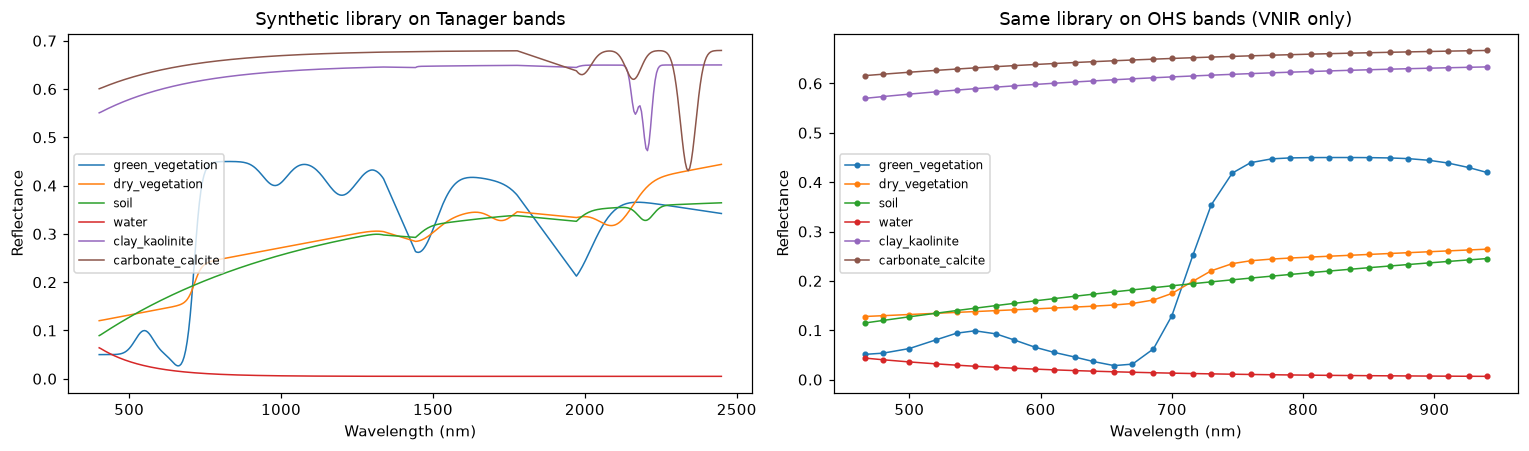

,401.29,700.91,1001.64,1302.34,1702.65,2191.27
green_vegetation,0.050,0.131,0.407,0.432,0.410,0.365
dry_vegetation,0.120,0.175,0.272,0.305,0.331,0.388
soil,0.089,0.190,0.257,0.299,0.335,0.329
water,0.064,0.013,0.006,0.005,0.005,0.005
clay_kaolinite,0.551,0.613,0.637,0.645,0.649,0.529
carbonate_calcite,0.601,0.651,0.669,0.676,0.679,0.652


In [2]:
lib1nm = hs.synthetic_library(np.arange(400.0, 2501.0, 1.0))  # six idealised spectra at 1 nm
print(lib1nm)
probe = hs.read_tanager(tanager_file("energy-mining"), window=(slice(0, 1), slice(0, 1)))  # Tanager bands and FWHM
w = hs.wavelengths(probe)
probe = probe.isel(band=np.flatnonzero(probe["good"].values & (w >= 400) & (w <= 2450)))  # bands the library covers
lib_tan = lib1nm.resample(probe)  # convolved with Tanager's band responses
lib_ohs = lib1nm.resample(np.array(hs.io.OHS_WAVELENGTHS), fwhm=15.0)  # OHS-like bands (assumed 15 nm FWHM)
minerals = lib_tan.subset("clay|carbonate")  # subset by a regular expression
print(lib_tan, "|", lib_ohs, "|", minerals.names)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
lib_tan.plot(ax=axes[0], lw=1); axes[0].set_title("Synthetic library on Tanager bands")
lib_ohs.plot(ax=axes[1], marker="o", ms=3, lw=1); axes[1].set_title("Same library on OHS bands (VNIR only)")
plt.tight_layout()
plt.show()
lib_tan.to_frame().iloc[:, ::60].round(3)  # every 60th band as a table

The library is resampled to Tanager's good bands between 400 and 2450 nm (the synthetic spectra
start at 400 nm). On these bands every absorption feature of the reference survives; on the 32 OHS bands only the
visible and NIR part exists, so clay and carbonate become indistinguishable from soil. Library
matching can only use the features a sensor can see.


## Similarity measures

To see how each measure treats brightness, a darker copy of the soil spectrum (half the reflectance,
as in shadow) and a brighter, slightly offset copy are added to the library and compared with the
originals.


In [3]:
soil = lib_tan.to_dict()["soil"]
test = hs.SpectralLibrary(lib_tan.wavelengths, np.vstack([lib_tan.spectra, 0.5 * soil, 1.3 * soil + 0.03]),
                          lib_tan.names + ["soil x 0.5 (shadow)", "soil x 1.3 + 0.03"])
cube_lib = hs.as_cube(test.spectra.T[:, None, :], test.wavelengths)  # library as a 1 x n cube
rows = {}
for m in ["sam", "sid", "sidsam", "sca", "euclidean"]:
    d = hs.spectral_similarity(cube_lib, lib_tan, measure=m).values[:, 0, :]  # (references, test spectra)
    rows[m] = pd.Series(d[lib_tan.names.index("soil")], index=test.names)
dist = pd.DataFrame(rows)
dist.round(3)

,sam,sid,sidsam,sca,euclidean
green_vegetation,0.295,0.140,0.043,0.619,2.129
dry_vegetation,0.092,0.008,0.001,0.225,0.596
soil,0.000,0.000,0.000,0.000,0.000
water,1.070,1.311,2.395,1.476,5.254
clay_kaolinite,0.244,0.077,0.019,0.653,6.713
carbonate_calcite,0.269,0.092,0.025,0.975,7.260
soil x 0.5 (shadow),0.000,0.000,0.000,0.000,2.693
soil x 1.3 + 0.03,0.020,0.001,0.000,0.000,2.164


Read the two last rows. SAM and SID give the shadowed soil a score of zero, because scaling does not
change the angle or the normalised shape; SCA also ignores the added offset, while SAM and SID
register it as a small shape change. Euclidean distance rates the shadowed soil as farther from soil
than some other materials are. For reflectance images with topography and shadow, angle based
measures are the usual choice; Euclidean distance is useful when brightness is diagnostic (water
against dark asphalt).


## A laboratory scene: sugar, salt and flour

Small training discs (radius 6 pixels) give one spectrum per class. Larger reference discs around
them, excluding the training pixels, are used to score each measure.


In [4]:
ssf = read_png_cube(DATA / "archive/data/sugar_salt_flour")  # (96, 256, 192)
shape = ssf.shape[1:]
centres = {"tray": (30, 100), "sugar": (110, 112), "flour": (160, 62), "salt": (190, 117)}  # (row, col)
train = {k: disc(shape, r, c, 6) for k, (r, c) in centres.items()}
refer = {k: disc(shape, r, c, 16) & ~train[k] for k, (r, c) in centres.items()}  # evaluation pixels
lab_lib = hs.library.from_dict({k: hs.mean_spectrum(ssf, m).values for k, m in train.items()}, hs.wavelengths(ssf))
print(lab_lib, lab_lib.names)

results, maps = [], {}
for m in ["sam", "sid", "sca", "euclidean"]:
    cls = hs.classify_spectral(ssf, lab_lib, measure=m)  # best match per pixel
    maps[m] = cls["class"].values
    correct = sum(int((maps[m][refer[k]] == i).sum()) for i, k in enumerate(lab_lib.names))
    total = sum(int(refer[k].sum()) for k in lab_lib.names)
    results.append({"measure": m, "accuracy on reference discs": correct / total})
pd.DataFrame(results).set_index("measure").round(3)

<SpectralLibrary 4 spectra, 96 bands 1293–2215 nm> ['tray', 'sugar', 'flour', 'salt']


,accuracy on reference discs
measure,
sam,1.000
sid,1.000
sca,1.000
euclidean,0.979


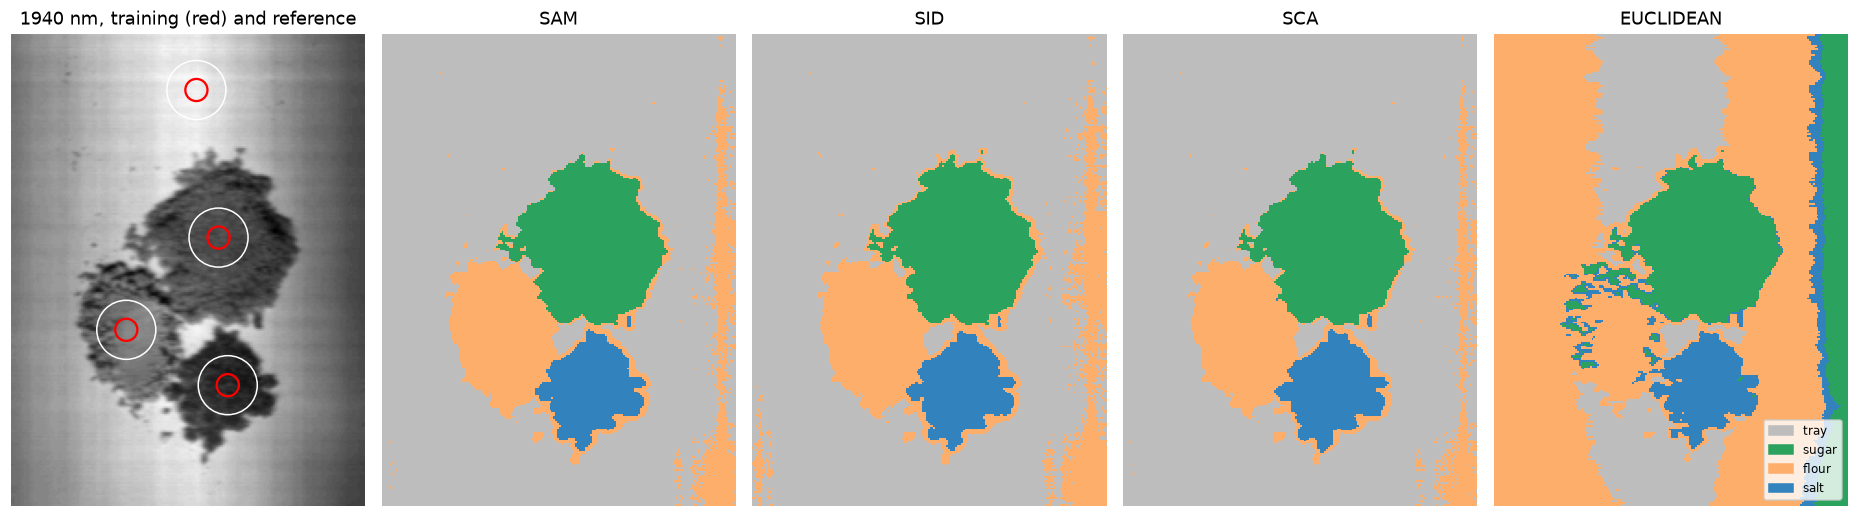

In [5]:
cmap = ListedColormap(["#bdbdbd", "#2ca25f", "#fdae6b", "#3182bd"])  # tray, sugar, flour, salt
fig, axes = plt.subplots(1, 5, figsize=(17, 4.6))
axes[0].imshow(hs.band_at(ssf, 1940), cmap="gray")
for k, (r, c) in centres.items():
    axes[0].add_patch(plt.Circle((c, r), 16, fill=False, color="w", lw=1))
    axes[0].add_patch(plt.Circle((c, r), 6, fill=False, color="r", lw=1.5))
axes[0].set_title("1940 nm, training (red) and reference")
for ax, (m, img) in zip(axes[1:], maps.items()):
    ax.imshow(img, cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest"); ax.set_title(m.upper())
axes[4].legend(handles=[Patch(color=c, label=n) for c, n in zip(cmap.colors, lab_lib.names)], fontsize=8, loc="lower right")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

SAM, SID and SCA classify every reference pixel correctly and give almost identical maps; their only
visible error is a strip of "flour" along the dark right edge of the tray. Euclidean distance is
slightly worse on the reference discs but much worse elsewhere: the tray is brighter in the middle
than at its sides (the lamp's illumination), and Euclidean distance, which follows brightness,
labels the darker parts of the tray as flour and the darkest edge as sugar or salt.


## An unknown material

The second scene holds the same powders plus a small white eraser hidden in the sugar. It is
classified with the library from the first scene, so the eraser has no class of its own. A SAM
threshold leaves pixels unclassified when even the best match is poor.


median best angle: eraser 6.0 deg, surrounding sugar 3.0 deg, scene 1.9 deg
threshold 9.2 deg | eraser pixels rejected: 30% | other pixels rejected: 0.9%


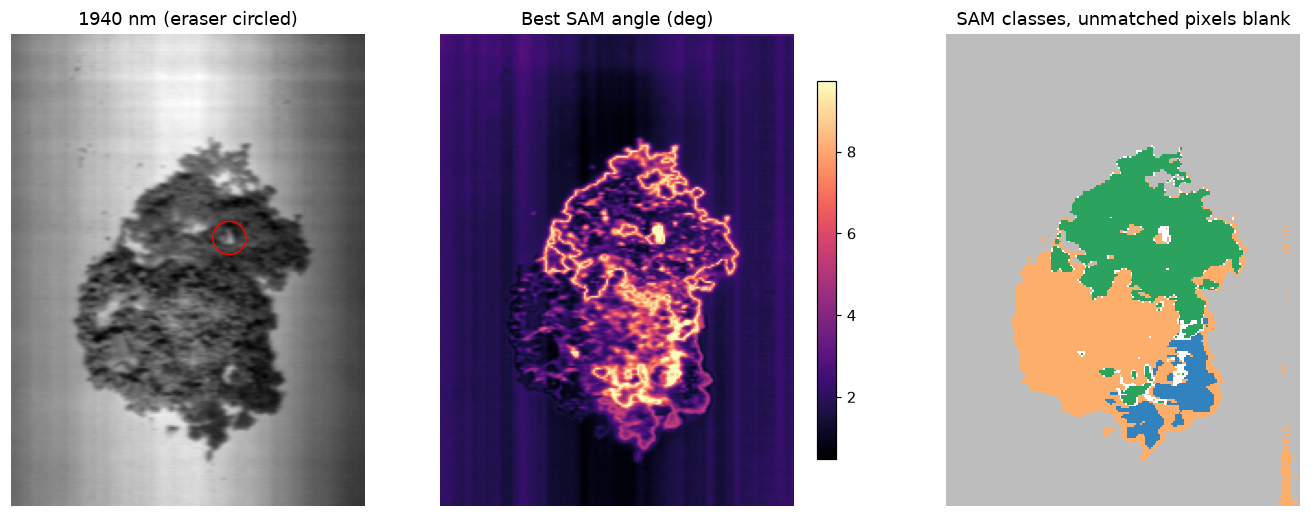

In [6]:
con = read_png_cube(DATA / "archive/data/sugar_salt_flour_contamination")  # same camera, another acquisition
sam_con = hs.sam(con, lab_lib)  # angle to each class (radians)
best = sam_con.min("target").values  # best angle per pixel
eraser = disc(con.shape[1:], 110, 118, 7)  # eraser location from the dataset's annotated preview
sugar_ring = disc(con.shape[1:], 110, 118, 25) & ~disc(con.shape[1:], 110, 118, 12)  # sugar around it
print(f"median best angle: eraser {np.degrees(np.median(best[eraser])):.1f} deg, "
      f"surrounding sugar {np.degrees(np.median(best[sugar_ring])):.1f} deg, scene {np.degrees(np.median(best)):.1f} deg")
thr = float(np.quantile(best, 0.99))  # reject the 1 percent worst matching pixels
cls_con = hs.classify_spectral(con, lab_lib, measure="sam", threshold=thr)
rejected = cls_con["class"].values == -1
print(f"threshold {np.degrees(thr):.1f} deg | eraser pixels rejected: {rejected[eraser].mean():.0%} | "
      f"other pixels rejected: {rejected[~eraser].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
axes[0].imshow(hs.band_at(con, 1940), cmap="gray"); axes[0].add_patch(plt.Circle((118, 110), 9, fill=False, color="r"))
axes[0].set_title("1940 nm (eraser circled)")
im = axes[1].imshow(np.degrees(best), cmap="magma", vmax=np.degrees(np.quantile(best, 0.995)))
axes[1].set_title("Best SAM angle (deg)"); plt.colorbar(im, ax=axes[1], shrink=0.8)
axes[2].imshow(np.where(rejected, np.nan, cls_con["class"].values), cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest")
axes[2].set_title("SAM classes, unmatched pixels blank")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The eraser's best match (a median of about 6 degrees) is twice as poor as that of the sugar around
it, so the eraser stands out as a bright spot in the angle map, and a threshold that rejects only
one percent of the scene rejects about a third of its pixels. The rest of the eraser's pixels are
mixed with sugar at its edge and still match sugar. The other rejected pixels lie along the
boundaries between piles, where powders mix. Matching against a library finds the eraser, but
crudely. This is the simplest form
of anomaly detection, and notebook 09_05_08 develops detectors that do much better.


## Minerals in the Permian Basin

Clays and carbonates are identified by their SWIR absorption features. The energy and mining scene
is matched over 2000 to 2450 nm, both on the raw spectra and on continuum removed spectra, against
the synthetic clay, carbonate, soil and dry vegetation spectra.


In [7]:
WIN = (slice(400, 650), slice(350, 600))
em = hs.read_tanager(tanager_file("energy-mining"), window=WIN, wavelength_range=(2000, 2450))
em = hs.smooth(em.isel(band=np.flatnonzero(em["good"].values)), window=7)  # good SWIR bands, lightly smoothed
em_cr = hs.continuum_removal(em)  # continuum removed image


def cr_library(lib):
    """Resample a library to the image bands and continuum remove it."""
    c = hs.resample_spectral(hs.as_cube(lib.spectra.T[:, None, :], lib.wavelengths), hs.wavelengths(em))
    return hs.SpectralLibrary(hs.wavelengths(em), hs.continuum_removal(c).values[:, 0, :].T, lib.names)


ref = lib_tan.subset(["clay_kaolinite", "carbonate_calcite", "soil", "dry_vegetation"])
syn = hs.classify_spectral(em_cr, cr_library(ref), measure="sam")  # synthetic references
pd.Series(syn["class"].values.ravel()).map(dict(enumerate(ref.names))).value_counts(normalize=True).to_frame("synthetic references")

,synthetic references
soil,1.0


With the idealised references almost every pixel goes to one class. The synthetic spectra have deep,
clean Gaussian features, while the real features here are 2 to 5 percent deep and sit on a noisy,
sloping continuum, so one reference happens to be closest to everything. This is the common failure
of matching against references that do not resemble the data, and the reason real libraries
(resampled with the sensor's response functions) or image references are used.

Image references come from the pixels with the strongest features. The band depth maps of notebook
09_05_02 pick the 25 pixels with the deepest carbonate feature (positioned between 2320 and 2365 nm)
and the 25 with the deepest clay feature; the scene median stands for background soil.


In [8]:
carb = hs.band_depth(em, 2340, 2270, 2400)  # carbonate feature
clay = hs.band_depth(em, 2205, 2120, 2260)  # clay feature
cd, kd = carb["depth"].values, clay["depth"].values
real = (carb["position"].values > 2320) & (carb["position"].values < 2365)  # carbonate minima at the right place
top_c = np.unravel_index(np.argsort(np.where(real, cd, -1).ravel())[-25:], cd.shape)  # deepest carbonate pixels
top_k = np.unravel_index(np.argsort(kd.ravel())[-25:], kd.shape)  # deepest clay pixels
X = em.values
img_lib = hs.library.from_dict({"carbonate rich": X[:, top_c[0], top_c[1]].mean(1),
                                "clay rich": X[:, top_k[0], top_k[1]].mean(1),
                                "background soil": np.nanmedian(X.reshape(X.shape[0], -1), 1)}, hs.wavelengths(em))
img_cr = cr_library(img_lib)
cr = hs.classify_spectral(em_cr, img_cr, measure="sam")
crc = cr["class"].values
summary = pd.DataFrame({"fraction": [np.mean(crc == i) for i in range(3)],
                        "median carbonate depth": [np.median(cd[crc == i]) for i in range(3)],
                        "median clay depth": [np.median(kd[crc == i]) for i in range(3)]}, index=img_lib.names)
summary.round(3)

,fraction,median carbonate depth,median clay depth
carbonate rich,0.006,0.054,0.013
clay rich,0.035,0.012,0.056
background soil,0.958,0.014,0.023


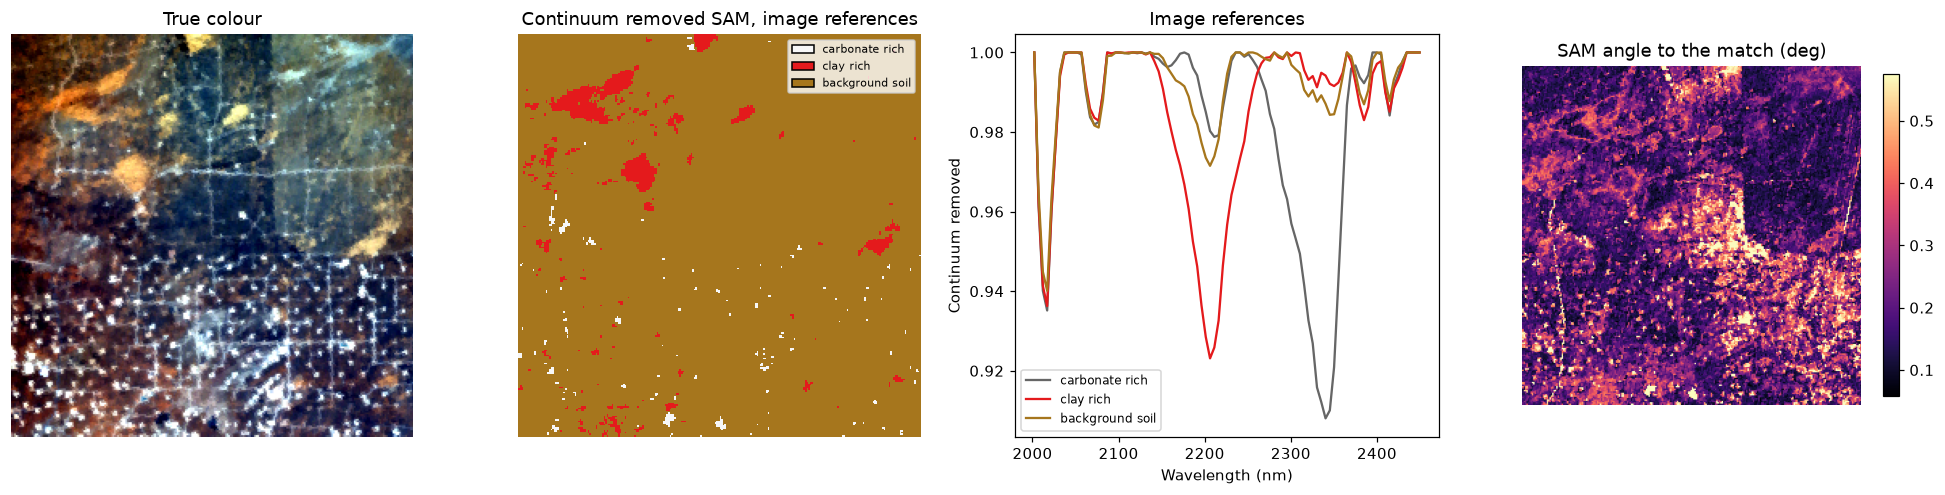

In [9]:
mcmap = ListedColormap(["#f7f7f7", "#e41a1c", "#a6761d"])  # carbonate, clay, background
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
hs.plot_rgb(hs.read_tanager(tanager_file("energy-mining"), window=WIN, bands=[37, 55, 17]), (651, 561, 461), ax=axes[0],
            title="True colour")
axes[1].imshow(crc, cmap=mcmap, vmin=-0.5, vmax=2.5, interpolation="nearest"); axes[1].axis("off")
axes[1].set_title("Continuum removed SAM, image references")
axes[1].legend(handles=[Patch(facecolor=c, edgecolor="k", label=n) for c, n in zip(mcmap.colors, img_lib.names)], fontsize=7)
for i, n in enumerate(img_lib.names):
    axes[2].plot(img_cr.wavelengths, img_cr.spectra[i], color=["0.4", "#e41a1c", "#a6761d"][i], label=n)
axes[2].set(xlabel="Wavelength (nm)", ylabel="Continuum removed", title="Image references"); axes[2].legend(fontsize=8)
im = axes[3].imshow(np.degrees(cr["score"]), cmap="magma", vmax=np.percentile(np.degrees(cr["score"]), 98))
axes[3].set_title("SAM angle to the match (deg)"); axes[3].axis("off"); plt.colorbar(im, ax=axes[3], shrink=0.8)
plt.tight_layout()
plt.show()

With image references the map follows the features: the carbonate rich class has about four times
the carbonate depth of the other classes, and the clay rich class has the deepest clay features
(compare the table). The carbonate pixels are the well pads and roads built from crushed caliche, a
few percent of the window; the clay rich class follows patches of soil, and the rest is background.
The continuum removed references show why: the carbonate reference has a clear minimum near 2340
nm, the clay reference near 2205 nm, and the background has weak versions of both. These are
relative classes defined by this scene; naming the minerals requires laboratory references and
field checks.


## An image library for a city

Image libraries come from labelled samples. Here 30 pixels per class are chosen by simple index
rules (as in notebook 09_05_00) and stored as a GeoDataFrame of points; `hs.from_image` averages
their spectra into a library, which then classifies the whole window with a SAM threshold.


In [10]:
urban = hs.drop_bad_bands(hs.read_tanager(tanager_file("urban"), window=(slice(319, 619), slice(285, 585))))
G, R, N, S1 = (hs.band_at(urban, w).values for w in (560, 650, 860, 1650))
ndvi, ndwi = (N - R) / (N + R), (G - N) / (G + N)
rules = {"water": ndwi > 0.3, "tree and grass": ndvi > 0.75,
         "bright roof": (ndvi < 0.15) & (S1 > np.nanquantile(S1, 0.97)),
         "dark pavement": (ndvi < 0.15) & (ndwi < 0) & (S1 < np.nanquantile(S1[ndvi < 0.15], 0.15)),
         "mixed residential": (ndvi > 0.35) & (ndvi < 0.5)}
rng = np.random.default_rng(0)
pts = []
for label, mask in rules.items():
    r, c = np.nonzero(mask)
    pick = rng.choice(len(r), min(30, len(r)), replace=False)  # 30 random pixels per class
    pts += [{"label": label, "row": int(rr), "col": int(cc), "x": float(urban.x[cc]), "y": float(urban.y[rr])}
            for rr, cc in zip(r[pick], c[pick])]
pts = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy([p["x"] for p in pts], [p["y"] for p in pts]), crs=urban.rio.crs)
city_lib = hs.from_image(urban, pts, "label", buffer=0)  # mean spectrum per label
print(city_lib, city_lib.names, "| points per class:", pts["label"].value_counts().to_dict())

<SpectralLibrary 5 spectra, 350 bands 401–2449 nm> ['bright roof', 'dark pavement', 'mixed residential', 'tree and grass', 'water'] | points per class: {'water': 30, 'tree and grass': 30, 'bright roof': 30, 'dark pavement': 30, 'mixed residential': 30}


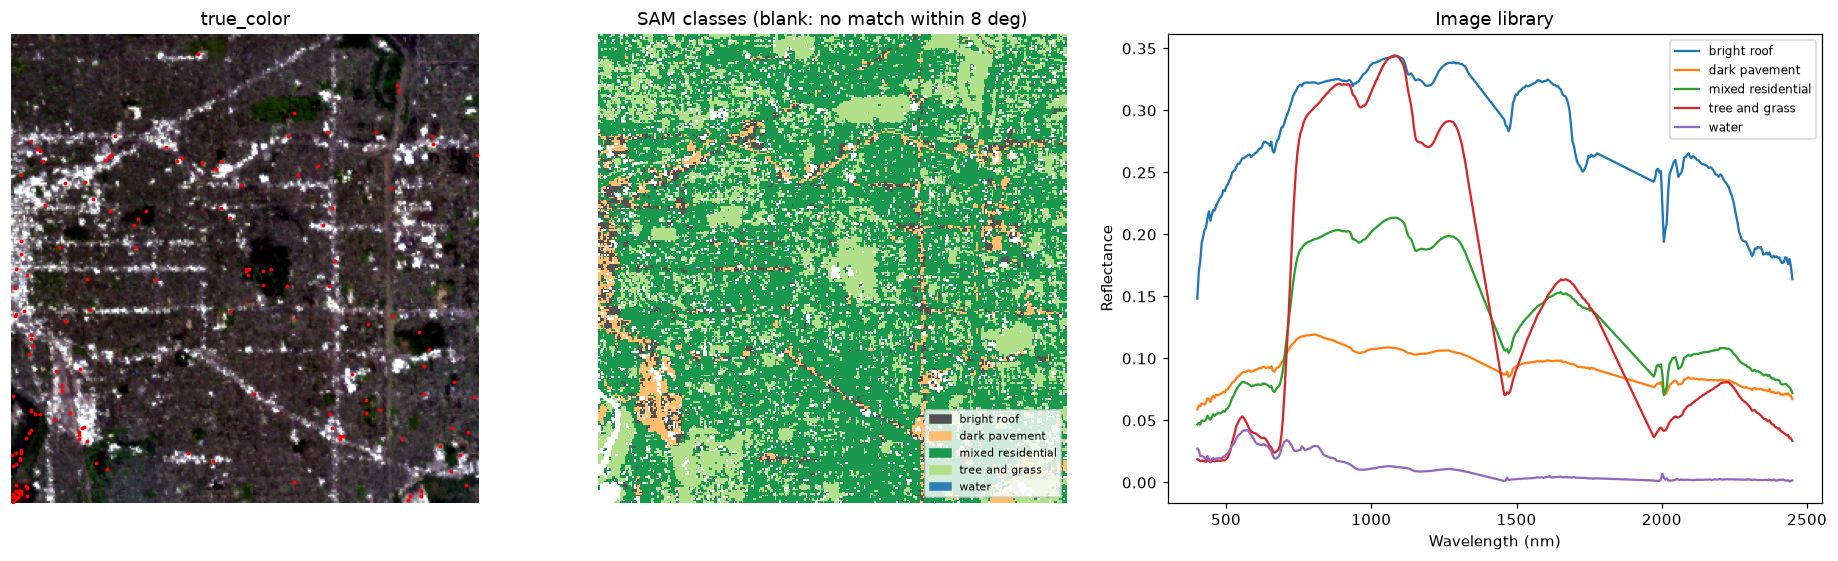

,fraction of window
mixed residential,0.609
tree and grass,0.218
unclassified,0.083
dark pavement,0.051
bright roof,0.040


In [11]:
cls_u = hs.classify_spectral(urban, city_lib, measure="sam", threshold=np.radians(8))  # unmatched beyond 8 degrees
ucmap = ListedColormap(["#525252", "#fdbf6f", "#1a9850", "#b2df8a", "#2c7fb8"])  # colours in library order
order = {n: i for i, n in enumerate(city_lib.names)}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.3]})
hs.plot_rgb(urban, "true_color", ax=axes[0])
axes[0].plot(pts["col"], pts["row"], "r.", ms=3)  # training pixels
img = np.where(cls_u["class"].values >= 0, cls_u["class"].values, np.nan)
axes[1].imshow(img, cmap=ucmap, vmin=-0.5, vmax=4.5, interpolation="nearest"); axes[1].axis("off")
axes[1].set_title("SAM classes (blank: no match within 8 deg)")
axes[1].legend(handles=[Patch(color=ucmap.colors[i], label=n) for n, i in order.items()], fontsize=7, loc="lower right")
city_lib.plot(ax=axes[2]); axes[2].set_title("Image library")
plt.tight_layout()
plt.show()
frac = pd.Series(cls_u["class"].values.ravel()).map({**{i: n for n, i in order.items()}, -1: "unclassified"})
frac.value_counts(normalize=True).round(3).to_frame("fraction of window")

The class map reproduces the city's structure: parks and tree lined streets, the large flat roofs
of commercial buildings and paved areas stand out from the mixed residential blocks, which cover
about 60 percent of the window. Water, although in the library, is not assigned at all. The window
holds only a thin strip of river, and water is so dark (1 to 3 percent reflectance) that noise
dominates its spectral shape: the water pixels lie a median of about 17 degrees from their own mean
spectrum, beyond the 8 degree threshold, so they stay unclassified. Angle measures are a poor choice
for very dark targets; a brightness rule or Euclidean distance works better for water. The red dots show where the training pixels came from: because the
rules pick extreme pixels for some classes, the library spectra are purer than typical pixels, which
is one reason mixed pixels end up in "mixed residential" or unclassified. Unmixing (notebook
09_05_07) models such pixels as mixtures instead.


## Summary and exercises

**Key points**

- Libraries must be resampled to the sensor; features outside the sensor's range or narrower than
  its bands cannot be matched.
- SAM, SID and SCA ignore brightness (SCA also offsets); Euclidean distance does not. Angle based
  measures suit images with shadows and topography.
- A library from small training regions classifies a laboratory scene almost perfectly; a threshold
  on the best score exposes materials missing from the library.
- Continuum removal makes matching depend on absorption features, which is essential for minerals.
- Image libraries from labelled points map urban surfaces quickly; mixed pixels remain a limitation.

**`geolattice.rsense.hyperspectral` functions used:** `SpectralLibrary`, `synthetic_library`,
`library.from_dict`, `from_image`, `as_cube`, `mean_spectrum`, `sam`,
`spectral_similarity`, `classify_spectral`, `continuum_removal`, `band_depth`, `resample_spectral`,
`smooth`, `read_tanager`, `drop_bad_bands`, `plot_rgb`.

**Exercises**

1. Classify the HACARUS `rice` scene with a library built from training discs on the three rice types
   and the eraser. Which measure works best?
2. Repeat the Permian Basin matching with SID and SID-SAM on the continuum removed spectra.
3. Change the city threshold to 5 and 12 degrees. How does the unclassified fraction change?
4. Download a few USGS splib07 spectra (for example kaolinite, calcite and montmorillonite, ASCII
   files of the `splib07a` set), read them with `hs.read_usgs(folder)`, resample them with
   `lib.resample(cube)` and repeat the mineral matching with real references.
